# 08 · Full photos, strategy 2: give the whole person to the model

In notebook 07 the fixed rule placed the head well only in a small part of the cases. Here we **remove the head crop**: the whole person box goes into the model.

```
Photo → YOLOX-s → person box ──(no head crop)──► letterbox 224×224 → frozen ResNet50 → vector (2,048) → output A
```

**Letterbox of the person:** we cut out the person box, scale it by k = 224 / max(width, height) without distortion, and center it on a black 224 × 224 canvas. Stretching it to 224 × 224 would squash a standing person.

**Expected drawback:** the head is about 1/7 of the height of a standing person, so in 224 px it is only ~30 px. In notebook 06 the head filled the crop.

## Two variants
| | Output | Trained on |
|---|---|---|
| **a) as is** | Output A from notebook 06 | head crops |
| **b) retrained** | Output A' with the same architecture and training settings | whole persons from the SHWD *train* photos |

Variant (a) shows what happens if only the input changes. Variant (b) is the fair comparison.

## Label of each person
SHWD labels heads, not persons. We give each detected person one labeled head:
1. Candidate heads: those with a side ≥ 32 px and at least 90% of their area inside the person box.
2. We choose the candidate whose center is closest to the point (cx, y1 + 0.1·h), where the head of that person should be. The distance is divided by h so that large persons are not favored.
3. Label of the person = label of that head (helmet or no helmet). Persons with no candidate head are not used, because we cannot know their label.

Limit: in crowds a box can hold several heads and take the head of another person (noisy label).

## Evaluation
For each labeled head in the *test* photos (side ≥ 32 px): it is *covered* if a detected person chose it as its head. Its decision is that person's (if several chose it, the one with the highest YOLOX score). Found and correct: a head that is not covered counts as an error.

Output: `models/helmet_person_head.keras` (output A'), used by the final system in notebook 10.

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from PIL import Image, ImageOps
from yolox_person_detector import detect_persons, intersection, area

keras.utils.set_random_seed(0)
REPO = Path.cwd().parent
SHWD = REPO / "data/VOC2028"
OUTPUTS, MODELS = REPO / "outputs", REPO / "models"
MIN_SIDE, SIZE = 32, 224

model = keras.models.load_model(MODELS / "helmet_and_color.keras")
inp = keras.Input((SIZE, SIZE, 3))
vectorize = keras.Model(inp, model.get_layer("resnet50")(model.get_layer("resnet_preprocess")(inp)))   # preprocessing + ResNet50 → vector
assert vectorize.predict(np.zeros((1, SIZE, SIZE, 3)), verbose=0).shape == (1, 2048)
output_A = model.get_layer("helmet_head")
split = {i: s for s in ["train", "val", "test"] for i in (SHWD / f"ImageSets/Main/{s}.txt").read_text().split()}

## 1. YOLOX on all photos, and person → head assignment

In [2]:
def labeled_heads(img_id):
    root = ET.parse(SHWD / f"Annotations/{img_id}.xml").getroot()
    H, y = [], []
    for o in root.iter("object"):
        if o.findtext("name") not in ("hat", "person"):
            continue
        b = [int(float(o.find("bndbox").findtext(t))) for t in ("xmin", "ymin", "xmax", "ymax")]
        if min(b[2] - b[0], b[3] - b[1]) >= MIN_SIDE:
            H.append(b); y.append(o.findtext("name") == "hat")
    return np.array(H, float).reshape(-1, 4), np.array(y, bool)

def assign(P, H):
    # Index of the labeled head chosen by each person (−1 if none)
    if not len(P) or not len(H):
        return np.full(len(P), -1)
    frac = intersection(P, H) / area(H)[None]                                  # fraction of each head inside each person
    h = P[:, 3] - P[:, 1]
    point = np.stack([(P[:, 0] + P[:, 2]) / 2, P[:, 1] + 0.1 * h], 1)          # where the head should be
    center_H = np.stack([(H[:, 0] + H[:, 2]) / 2, (H[:, 1] + H[:, 3]) / 2], 1)
    dist = np.linalg.norm(point[:, None] - center_H[None], axis=2) / h[:, None]
    dist[frac < 0.9] = np.inf
    return np.where(np.isinf(dist.min(1)), -1, dist.argmin(1))

def letterbox(img, b):
    x1, y1, x2, y2 = np.clip(b, 0, [img.width, img.height, img.width, img.height])
    p = img.crop((x1, y1, x2, y2))
    k = SIZE / max(p.width, p.height)
    p = p.resize((max(1, round(p.width * k)), max(1, round(p.height * k))), Image.BILINEAR)
    canvas = Image.new("RGB", (SIZE, SIZE))
    canvas.paste(p, ((SIZE - p.width) // 2, (SIZE - p.height) // 2))
    return np.asarray(canvas)

rows, X = [], []
for img_id, part in split.items():
    H, yH = labeled_heads(img_id)
    if not len(H):
        continue
    img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
    P, score = detect_persons(img)
    chosen = assign(P, H)
    for j in range(len(H)):                                                    # one row per labeled head
        who = np.where(chosen == j)[0]
        i = who[score[who].argmax()] if len(who) else -1
        rows.append({"id": img_id, "split": part, "true_helmet": yH[j], "covered": i >= 0, "row_X": len(X) if i >= 0 else -1})
        if i >= 0:
            X.append(letterbox(img, P[i]))
heads = pd.DataFrame(rows)
X = np.stack(X)
print(X.shape)
pd.crosstab(heads.split, [heads.true_helmet, heads.covered], margins=True)

(24280, 224, 224, 3)


true_helmet False         True          All
covered     False   True False  True       
split                                      
test         1617   3816   206  1077   6716
train        5813  13814   777  3675  24079
val           619   1417    81   481   2598
All          8049  19047  1064  5233  33393

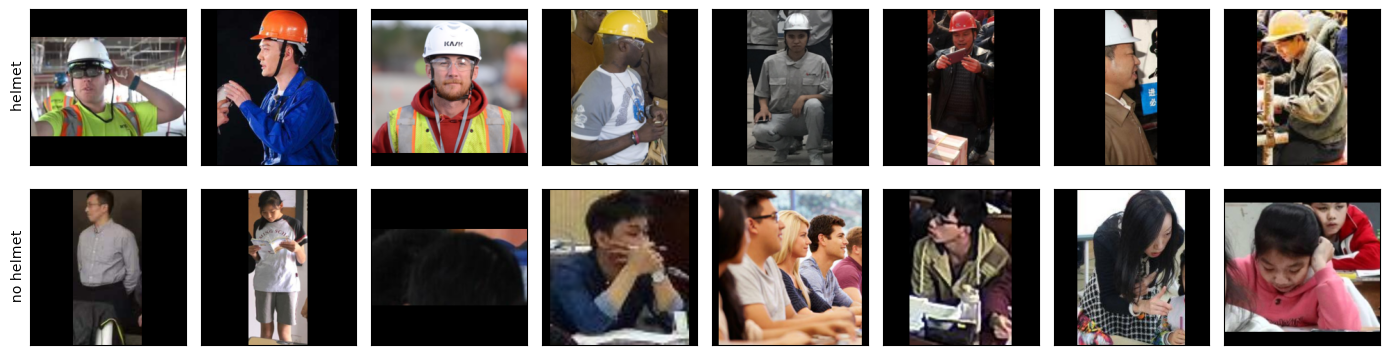

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for row, label in enumerate([True, False]):
    idx = heads[(heads.true_helmet == label) & heads.covered].row_X.sample(8, random_state=0)
    for ax, k in zip(axes[row], idx):
        ax.imshow(X[k]); ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel("helmet" if label else "no helmet")
plt.tight_layout(); plt.savefig(OUTPUTS / "08_persons_letterbox.png", dpi=120); plt.show()

## 2. ResNet50 vectors and the two variants

In [4]:
V = np.concatenate([vectorize.predict(X[i:i + 1024].astype("float32"), batch_size=64, verbose=0) for i in range(0, len(X), 1024)])
c = heads[heads.covered]
sel = {p: c[c.split == p] for p in ["train", "val", "test"]}

# b) output A' retrained on whole persons
output_Ap = keras.Sequential([keras.Input((2048,)), layers.Dropout(0.3),
                              layers.Dense(1, activation="sigmoid", kernel_regularizer=keras.regularizers.l2(1e-3))])
output_Ap.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
ytr = sel["train"].true_helmet.to_numpy().astype(int)
n = np.bincount(ytr)
output_Ap.fit(V[sel["train"].row_X], ytr, validation_data=(V[sel["val"].row_X], sel["val"].true_helmet.astype(int)),
              epochs=60, batch_size=64, verbose=0, class_weight={k: len(ytr) / (2 * n[k]) for k in (0, 1)},
              callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
print("training persons: no helmet", n[0], "| helmet", n[1])

training persons: no helmet 13814 | helmet 3675


## 3. Comparison on the test photos

Same labeled heads and same measures as notebook 07:
- **coverage** = covered heads / labeled heads
- **sensitivity no helmet** = heads without a helmet decided "no helmet" / covered heads without a helmet
- **specificity** = heads with a helmet decided "helmet" / covered heads with a helmet
- **found and correct** = covered and correctly decided heads / all labeled heads

In [5]:
t = heads[heads.split == "test"].copy()
for name, output in [("whole person, output A as is", output_A), ("whole person, output A' retrained", output_Ap)]:
    t[name] = None
    k = t.covered
    t.loc[k, name] = output.predict(V[t.row_X[k]], verbose=0).ravel() >= 0.5

def metrics(true, covered, pred):
    true, cov = np.asarray(true, bool), np.asarray(covered, bool)
    pred_cov = np.asarray(pred, dtype=object)[cov].astype(bool)      # pred is None/NaN where nothing covers the head
    correct = np.zeros(len(true), bool)
    correct[cov] = pred_cov == true[cov]
    return {"coverage": cov.mean(),
            "sensitivity no helmet": (~pred_cov[~true[cov]]).mean() if (~true[cov]).any() else np.nan,
            "specificity helmet": pred_cov[true[cov]].mean() if true[cov].any() else np.nan,
            "found and correct": correct.mean()}

comparison = pd.read_csv(OUTPUTS / "07_comparison.csv", index_col=0)
for name in ["whole person, output A as is", "whole person, output A' retrained"]:
    comparison.loc[name] = metrics(t.true_helmet, t.covered, t[name])
comparison.to_csv(OUTPUTS / "08_comparison.csv")
comparison.round(3)

,coverage,sensitivity no helmet,specificity helmet,found and correct
fixed rule (07),0.168,0.935,0.993,0.161
"whole person, output A as is",0.729,0.893,0.997,0.667
"whole person, output A' retrained",0.729,0.987,0.976,0.717


## 4. Save output A' for notebook 10

In [6]:
output_Ap.save(MODELS / "helmet_person_head.keras")